# ML Lab-5
## Soham Admane 
### C2-B1-08 
### 03.09.2026

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('diabetes (6).csv')

In [3]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
df.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [5]:
df.shape

(768, 9)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [7]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [8]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='str')

# Univariate Analysis

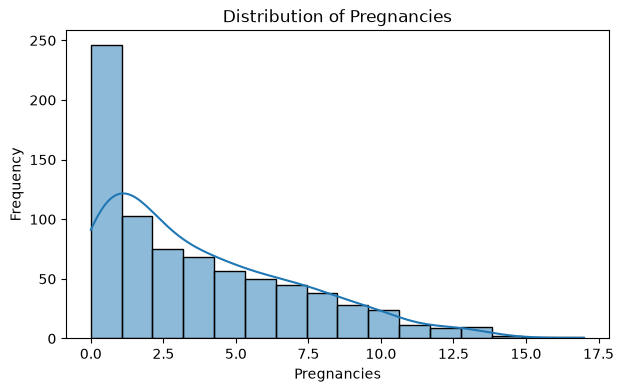

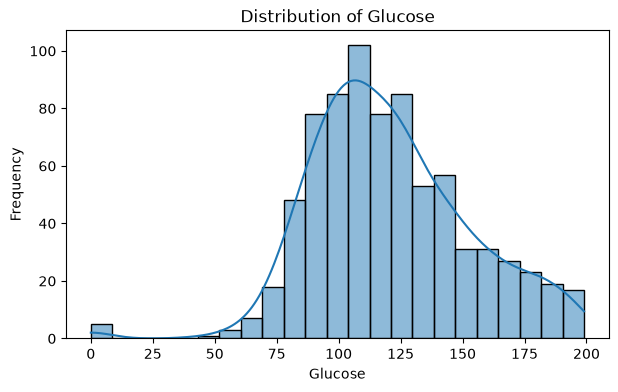

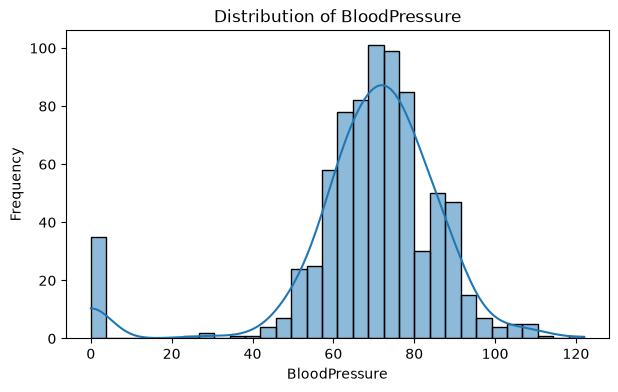

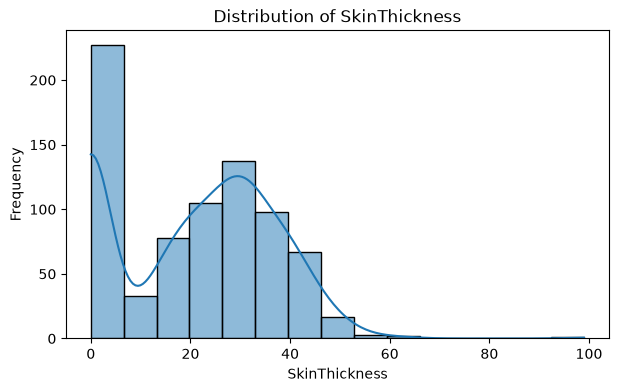

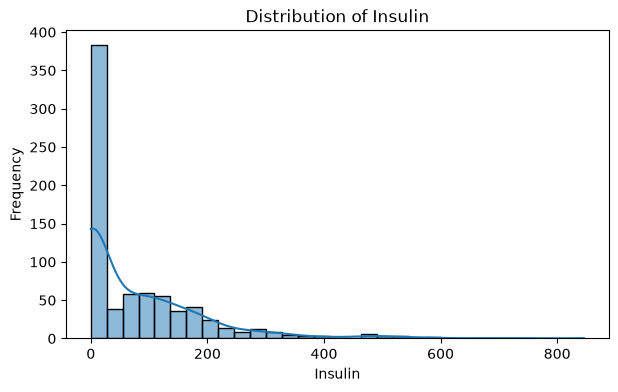

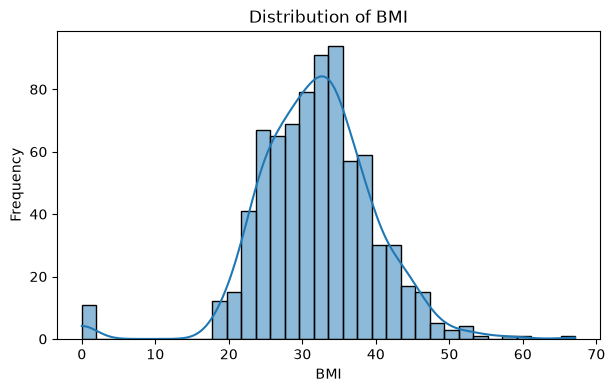

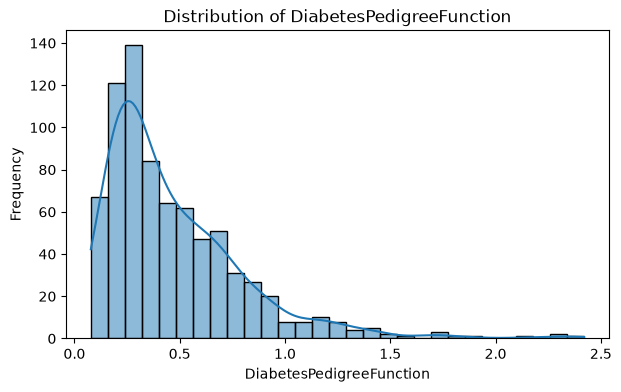

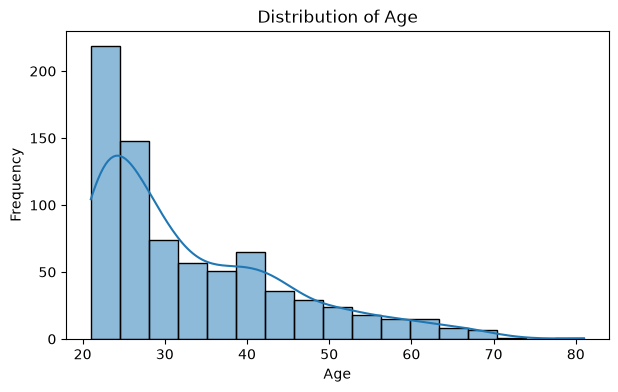

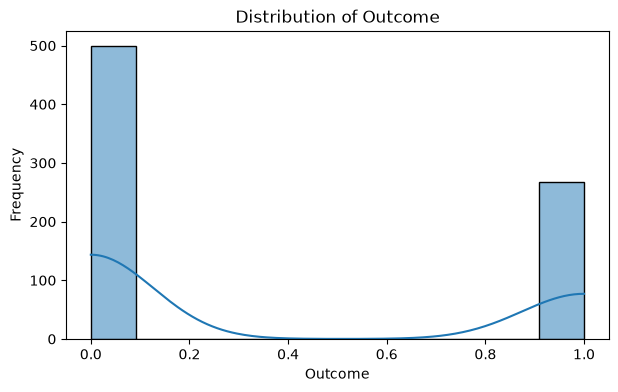

In [11]:
numeric_cols = df.columns.tolist()

for col in numeric_cols:
    plt.figure(figsize=(7, 4))
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

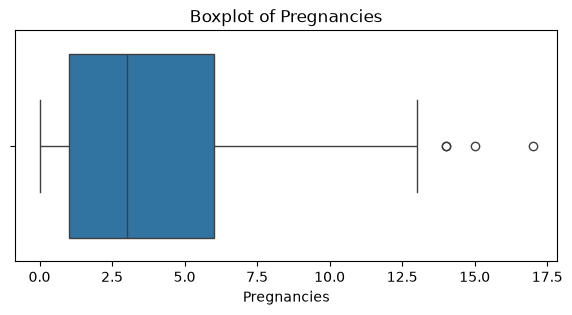

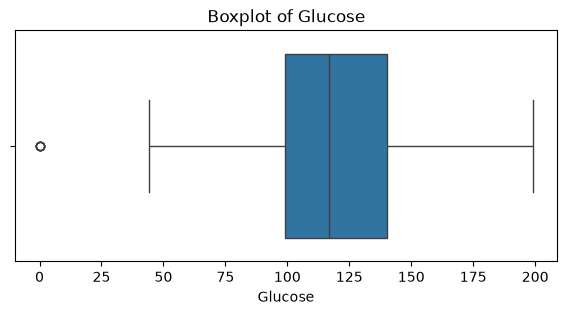

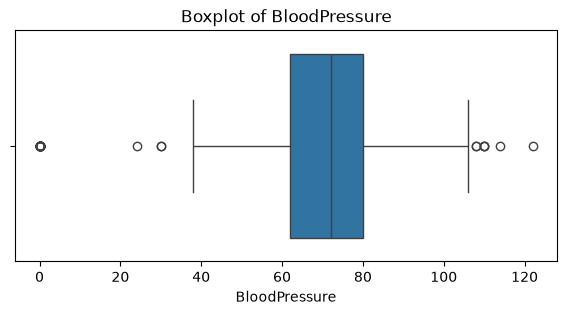

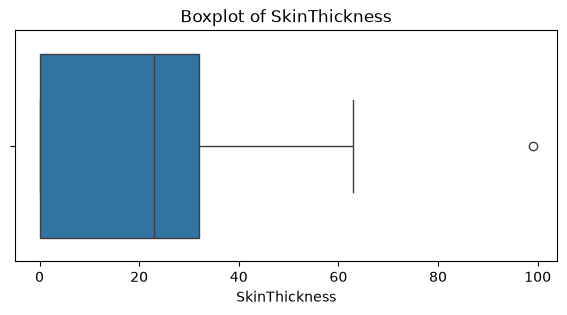

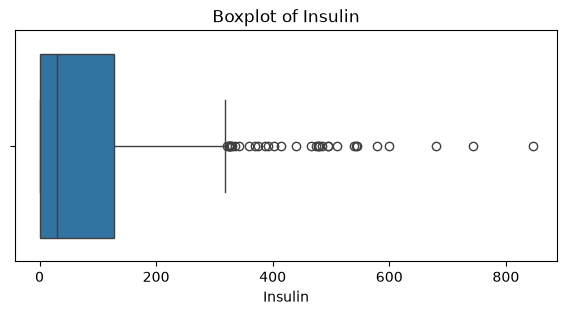

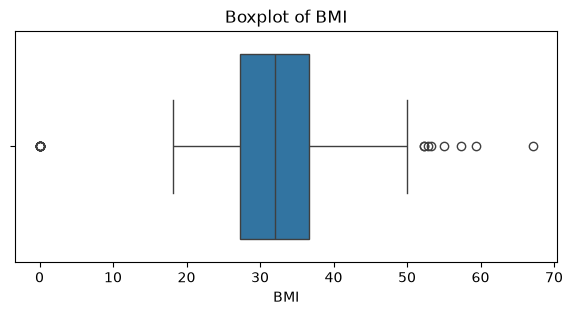

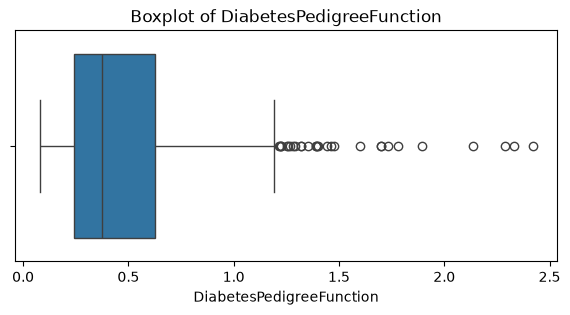

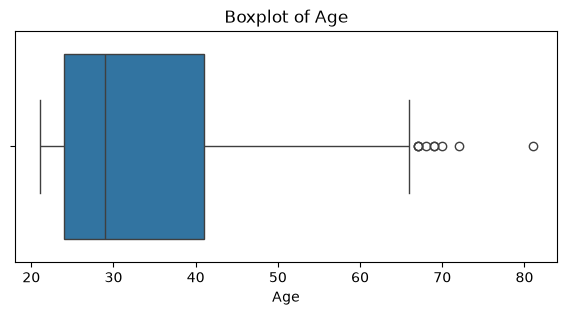

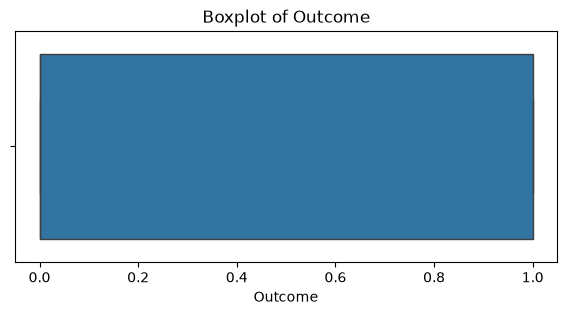

In [12]:
# Boxplot - Outlier Analysis
for col in numeric_cols:
    plt.figure(figsize=(7, 3))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

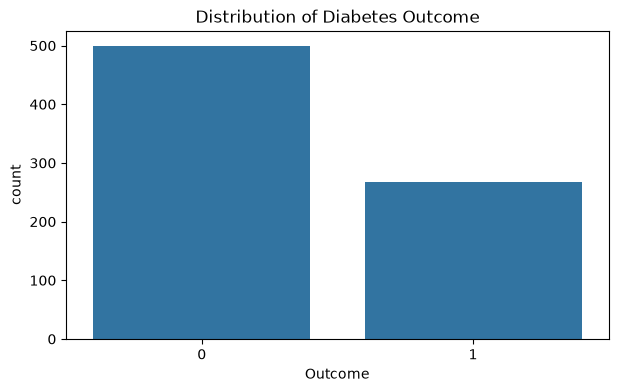

In [13]:
plt.figure(figsize=(7, 4))
sns.countplot(x='Outcome', data=df)
plt.title('Distribution of Diabetes Outcome')
plt.show()

In [14]:
df['Outcome'].value_counts().sort_index()

Outcome
0    500
1    268
Name: count, dtype: int64

# Bivariate Analysis

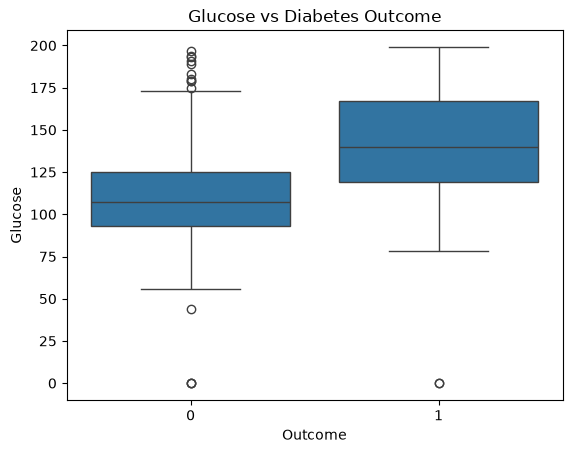

In [15]:
# Glucose vs Outcome
sns.boxplot(x='Outcome', y='Glucose', data=df)
plt.title('Glucose vs Diabetes Outcome')
plt.show()

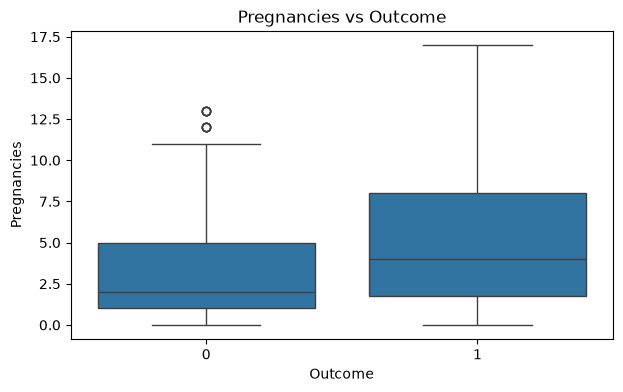

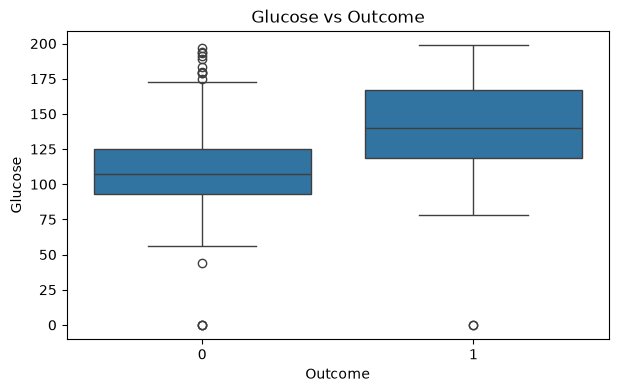

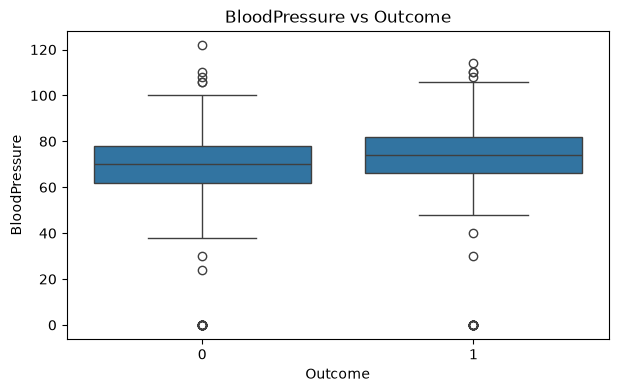

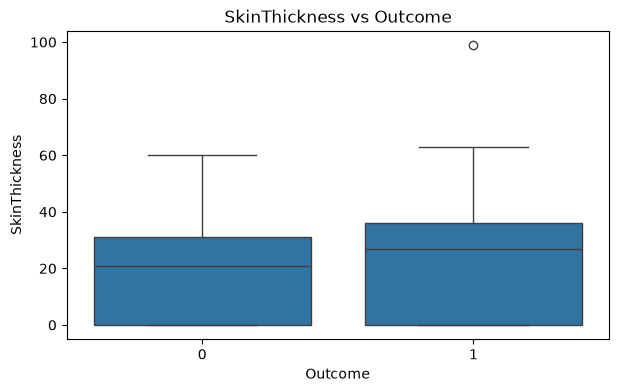

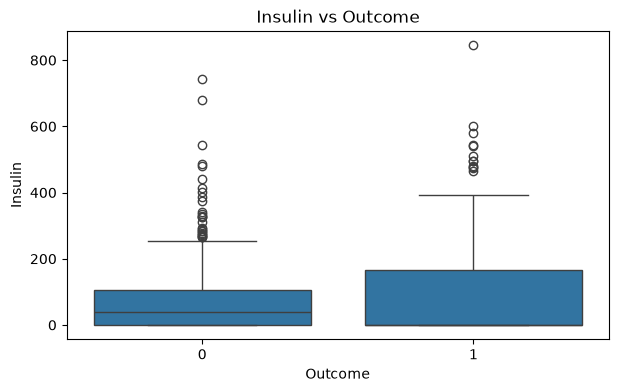

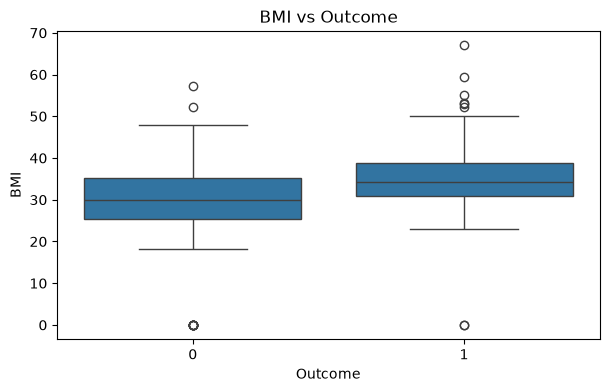

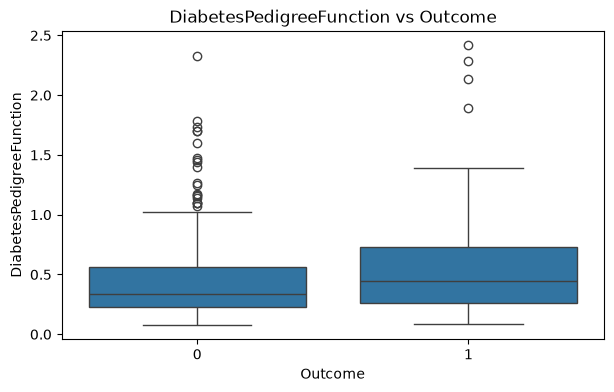

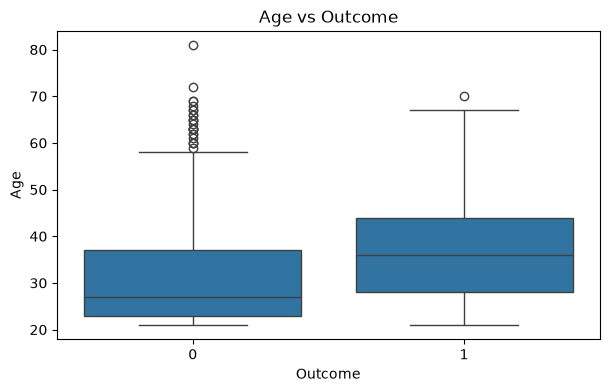

In [16]:
features = [
    'Pregnancies',
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
    'DiabetesPedigreeFunction',
    'Age',
]

for col in features:
    plt.figure(figsize=(7, 4))
    sns.boxplot(x='Outcome', y=col, data=df)
    plt.title(f'{col} vs Outcome')
    plt.xlabel('Outcome')
    plt.ylabel(col)
    plt.show()

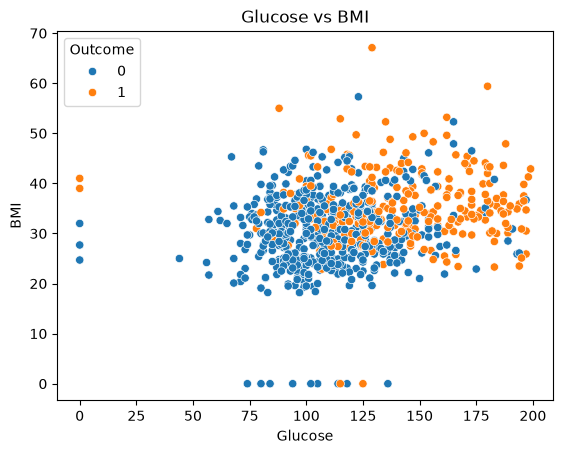

In [17]:
# Scatter Plot
sns.scatterplot(x='Glucose', y='BMI', hue='Outcome', data=df)
plt.title('Glucose vs BMI')
plt.show()

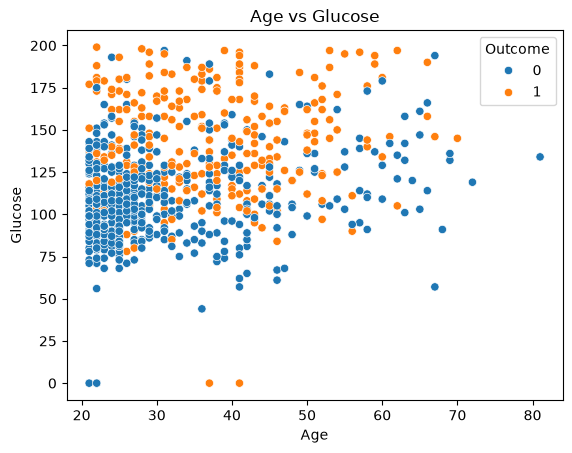

In [18]:
sns.scatterplot(x='Age', y='Glucose', hue='Outcome', data=df)
plt.title('Age vs Glucose')
plt.show()

# Multivariate Analysis

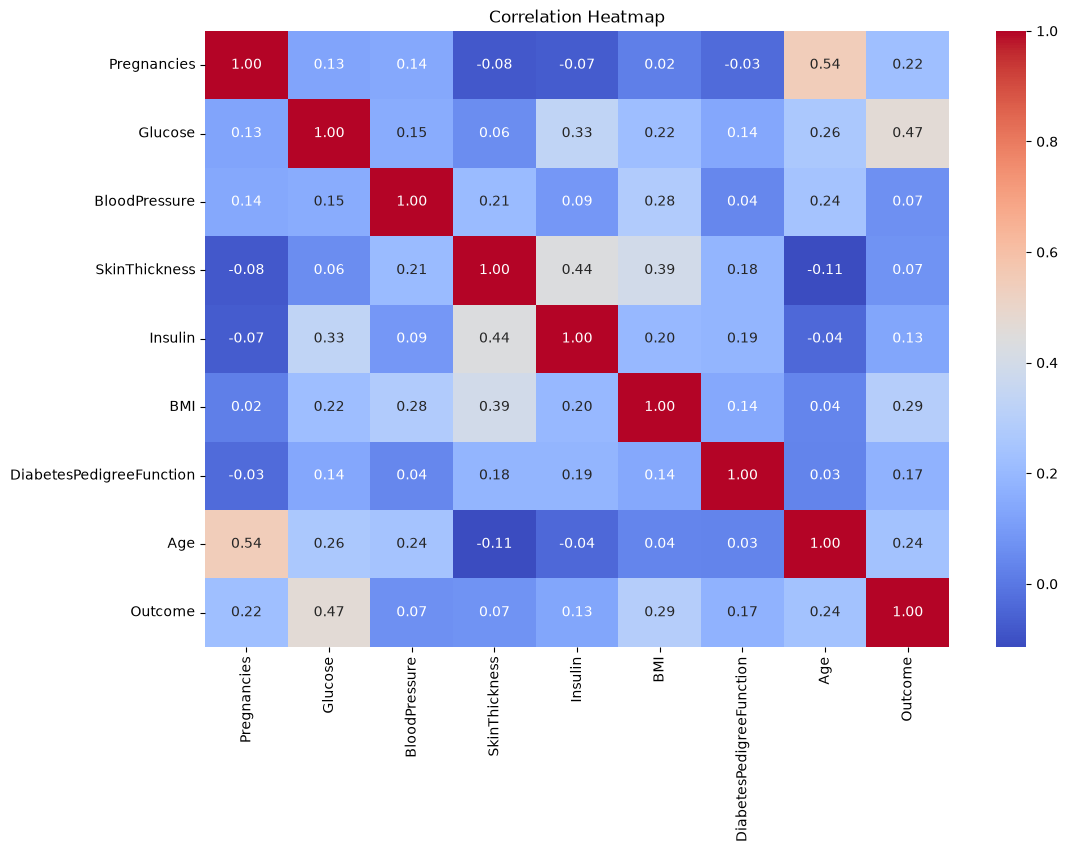

In [19]:
plt.figure(figsize=(12, 8))
corr = df.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

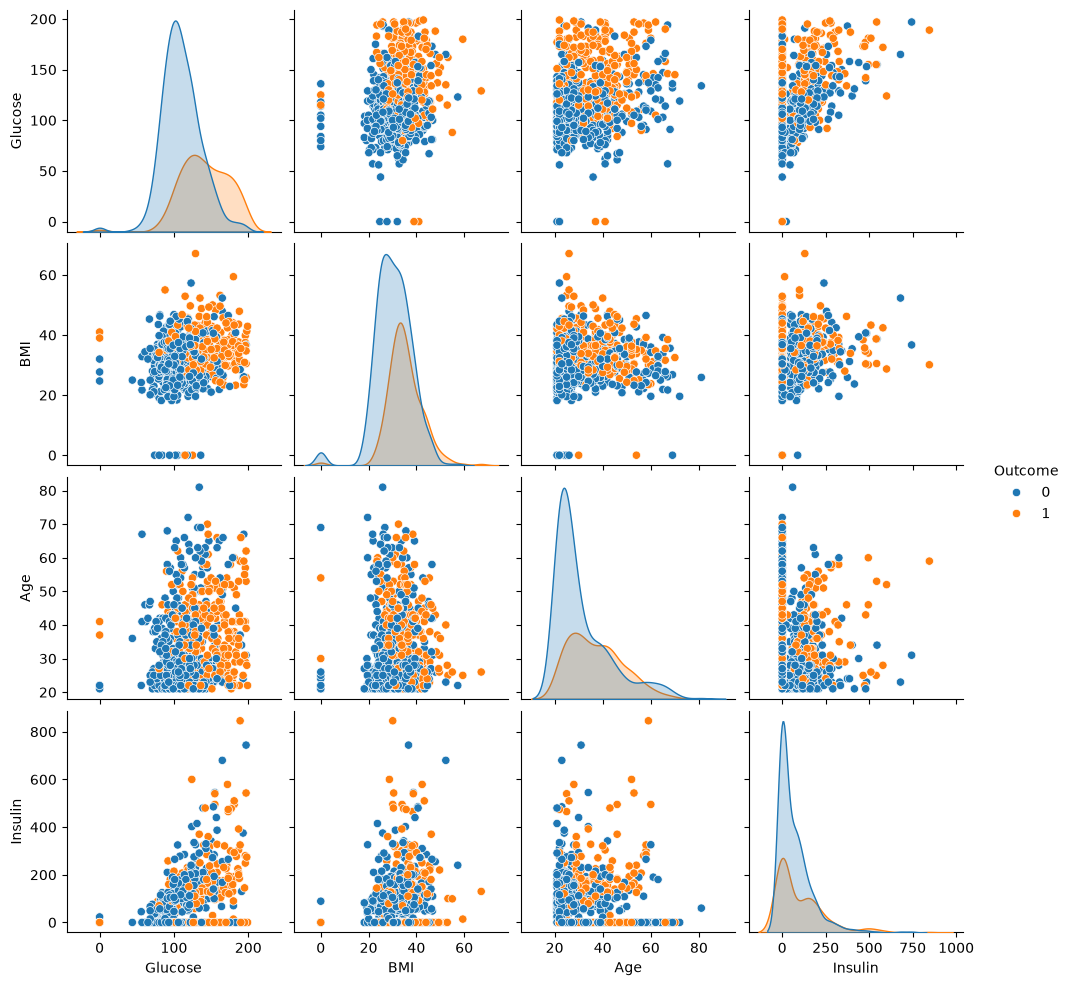

In [20]:
selected = ['Glucose', 'BMI', 'Age', 'Insulin', 'Outcome']
sns.pairplot(df[selected], hue='Outcome')
plt.show()

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

In [22]:
x = df.drop('Outcome', axis=1)
y = df['Outcome']

In [23]:
print("X shape:", x.shape)
print("Y shape:", y.shape)

X shape: (768, 8)
Y shape: (768,)


In [24]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

In [25]:
print("x_train:", x_train.shape)
print("x_test:", x_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

x_train: (614, 8)
x_test: (154, 8)
y_train: (614,)
y_test: (154,)


In [26]:
# Feature Scaling (KNN is distance-based, scaling is essential)
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

# KNN Classifier

In [27]:
knn_clf = KNeighborsClassifier(n_neighbors=5)
knn_clf.fit(x_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [28]:
y_train_pred_clf = knn_clf.predict(x_train_scaled)
y_test_pred_clf = knn_clf.predict(x_test_scaled)

In [29]:
train_accuracy = accuracy_score(y_train, y_train_pred_clf)
print("Training Accuracy:", train_accuracy)

Training Accuracy: 0.8061889250814332


In [30]:
test_accuracy = accuracy_score(y_test, y_test_pred_clf)
print("Testing Accuracy:", test_accuracy)

Testing Accuracy: 0.7012987012987013


In [31]:
print("Precision:", precision_score(y_test, y_test_pred_clf, average='weighted'))
print("Recall:",    recall_score(y_test, y_test_pred_clf, average='weighted'))
print("F1 Score:", f1_score(y_test, y_test_pred_clf, average='weighted'))

Precision: 0.6946214163195296
Recall: 0.7012987012987013
F1 Score: 0.6968633878970829


In [32]:
print(classification_report(y_test, y_test_pred_clf))

              precision    recall  f1-score   support

           0       0.75      0.80      0.78       100
           1       0.58      0.52      0.55        54

    accuracy                           0.70       154
   macro avg       0.67      0.66      0.66       154
weighted avg       0.69      0.70      0.70       154



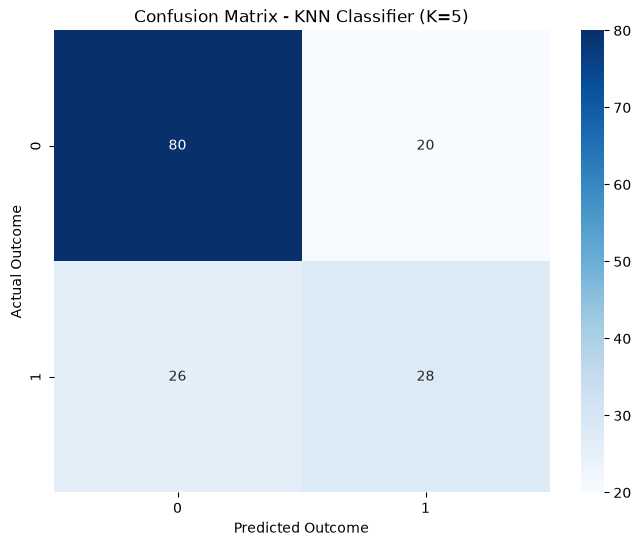

In [33]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred_clf)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Outcome')
plt.ylabel('Actual Outcome')
plt.title('Confusion Matrix - KNN Classifier (K=5)')
plt.show()

# Comparing Performance for Different Values of K

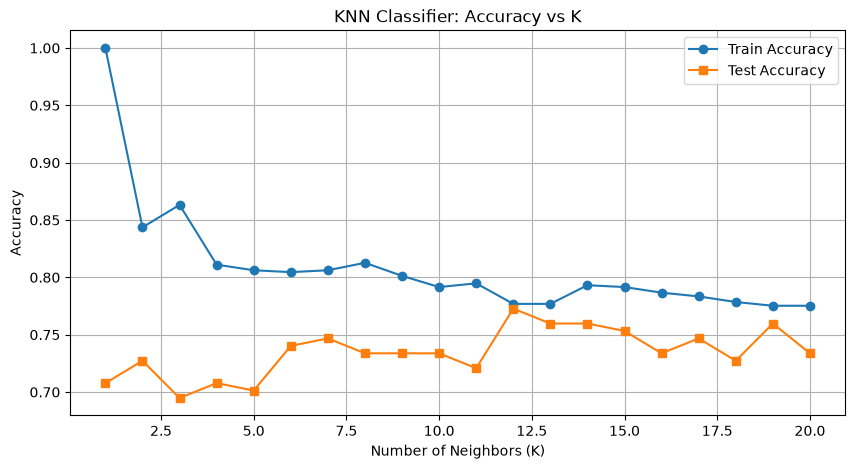

In [34]:
k_values = range(1, 21)
train_accuracies = []
test_accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(x_train_scaled, y_train)
    train_accuracies.append(accuracy_score(y_train, knn.predict(x_train_scaled)))
    test_accuracies.append(accuracy_score(y_test, knn.predict(x_test_scaled)))

plt.figure(figsize=(10, 5))
plt.plot(k_values, train_accuracies, label='Train Accuracy', marker='o')
plt.plot(k_values, test_accuracies, label='Test Accuracy', marker='s')
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Accuracy')
plt.title('KNN Classifier: Accuracy vs K')
plt.legend()
plt.grid(True)
plt.show()

In [35]:
best_k = k_values[test_accuracies.index(max(test_accuracies))]
print(f"Best K: {best_k}, Test Accuracy: {max(test_accuracies):.4f}")

Best K: 12, Test Accuracy: 0.7727


# Decision Boundary Visualization (KNN Classifier)

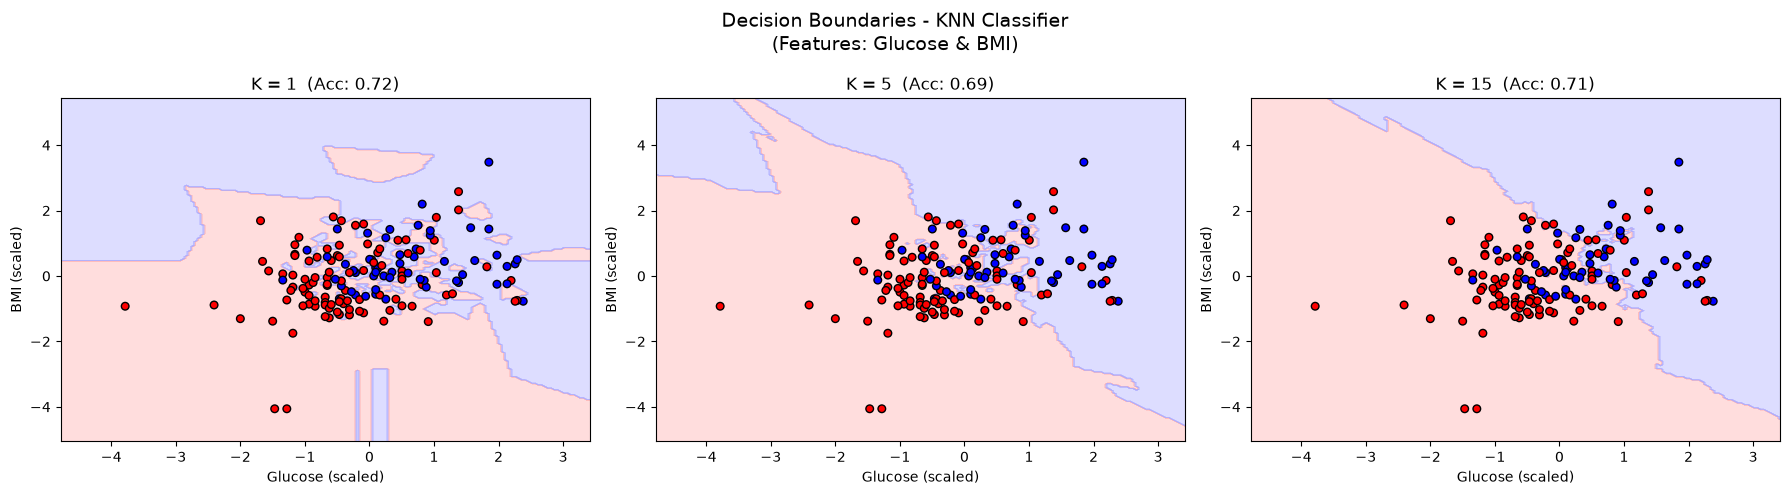

In [36]:
from matplotlib.colors import ListedColormap

# Use only Glucose and BMI for 2D visualization
x_vis = df[['Glucose', 'BMI']].values
y_vis = df['Outcome'].values

scaler_vis = StandardScaler()
x_vis_scaled = scaler_vis.fit_transform(x_vis)

x_train_v, x_test_v, y_train_v, y_test_v = train_test_split(
    x_vis_scaled, y_vis, test_size=0.2, random_state=42, stratify=y_vis
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
k_plot_values = [1, 5, 15]

cmap_light = ListedColormap(['#FFAAAA', '#AAAAFF'])
cmap_bold  = ListedColormap(['#FF0000', '#0000FF'])

for ax, k in zip(axes, k_plot_values):
    knn_v = KNeighborsClassifier(n_neighbors=k)
    knn_v.fit(x_train_v, y_train_v)

    h = 0.05
    x_min, x_max = x_vis_scaled[:, 0].min() - 1, x_vis_scaled[:, 0].max() + 1
    y_min, y_max = x_vis_scaled[:, 1].min() - 1, x_vis_scaled[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))
    Z = knn_v.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.4, cmap=cmap_light)
    ax.scatter(x_test_v[:, 0], x_test_v[:, 1], c=y_test_v,
               cmap=cmap_bold, edgecolors='k', s=30)
    acc = accuracy_score(y_test_v, knn_v.predict(x_test_v))
    ax.set_title(f'K = {k}  (Acc: {acc:.2f})')
    ax.set_xlabel('Glucose (scaled)')
    ax.set_ylabel('BMI (scaled)')

plt.suptitle('Decision Boundaries - KNN Classifier\n(Features: Glucose & BMI)', fontsize=14)
plt.tight_layout()
plt.show()

# KNN Regressor

In [37]:
# Use Glucose as continuous target for regression
x_reg = df.drop(columns=['Glucose', 'Outcome'])
y_reg = df['Glucose']

x_train_r, x_test_r, y_train_r, y_test_r = train_test_split(
    x_reg, y_reg, test_size=0.2, random_state=42
)

scaler_r = StandardScaler()
x_train_r_scaled = scaler_r.fit_transform(x_train_r)
x_test_r_scaled  = scaler_r.transform(x_test_r)

In [38]:
knn_reg = KNeighborsRegressor(n_neighbors=5)
knn_reg.fit(x_train_r_scaled, y_train_r)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


In [39]:
y_train_pred_reg = knn_reg.predict(x_train_r_scaled)
y_test_pred_reg  = knn_reg.predict(x_test_r_scaled)

In [40]:
print("--- KNN Regressor Metrics (K=5) ---")
print(f"Train R² Score:  {r2_score(y_train_r, y_train_pred_reg):.4f}")
print(f"Test  R² Score:  {r2_score(y_test_r, y_test_pred_reg):.4f}")
print(f"Train MAE: {mean_absolute_error(y_train_r, y_train_pred_reg):.4f}")
print(f"Test  MAE: {mean_absolute_error(y_test_r, y_test_pred_reg):.4f}")
print(f"Train RMSE: {np.sqrt(mean_squared_error(y_train_r, y_train_pred_reg)):.4f}")
print(f"Test  RMSE: {np.sqrt(mean_squared_error(y_test_r, y_test_pred_reg)):.4f}")

--- KNN Regressor Metrics (K=5) ---
Train R² Score:  0.4132
Test  R² Score:  -0.0197
Train MAE: 18.3606
Test  MAE: 25.0584
Train RMSE: 24.5201
Test  RMSE: 32.0331


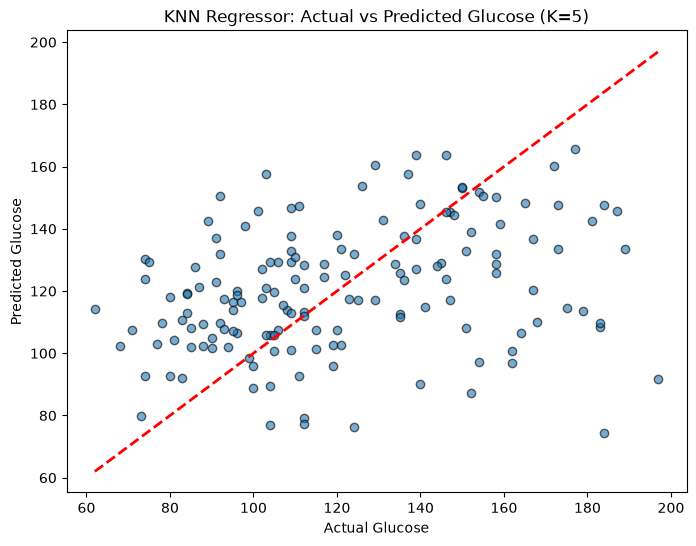

In [41]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test_r, y_test_pred_reg, alpha=0.6, edgecolors='k')
plt.plot([y_test_r.min(), y_test_r.max()],
         [y_test_r.min(), y_test_r.max()], 'r--', lw=2)
plt.xlabel('Actual Glucose')
plt.ylabel('Predicted Glucose')
plt.title('KNN Regressor: Actual vs Predicted Glucose (K=5)')
plt.show()

# Comparing Regressor Performance for Different Values of K

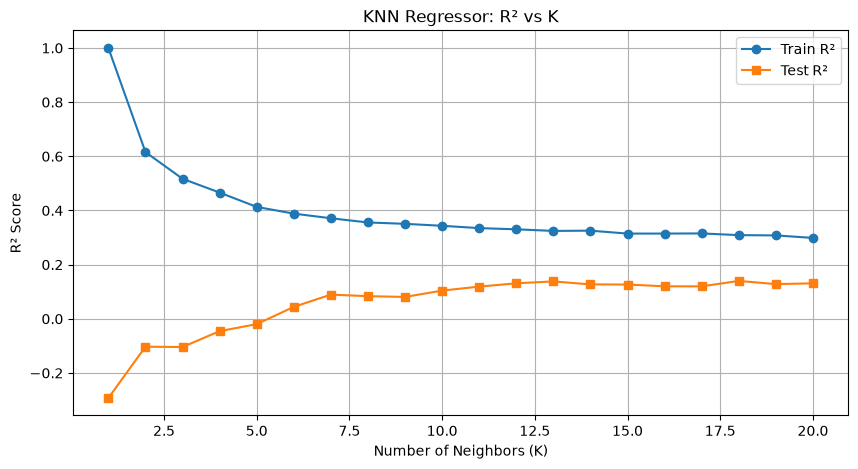

In [42]:
k_values_r = range(1, 21)
train_r2_list = []
test_r2_list  = []

for k in k_values_r:
    knn_r = KNeighborsRegressor(n_neighbors=k)
    knn_r.fit(x_train_r_scaled, y_train_r)
    train_r2_list.append(r2_score(y_train_r, knn_r.predict(x_train_r_scaled)))
    test_r2_list.append(r2_score(y_test_r, knn_r.predict(x_test_r_scaled)))

plt.figure(figsize=(10, 5))
plt.plot(k_values_r, train_r2_list, label='Train R²', marker='o')
plt.plot(k_values_r, test_r2_list,  label='Test R²',  marker='s')
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('R² Score')
plt.title('KNN Regressor: R² vs K')
plt.legend()
plt.grid(True)
plt.show()

In [43]:
best_k_reg = list(k_values_r)[test_r2_list.index(max(test_r2_list))]
print(f"Best K (Regressor): {best_k_reg}, Test R²: {max(test_r2_list):.4f}")

Best K (Regressor): 18, Test R²: 0.1399


# Summary

In [44]:
# Summary of KNN Classifier at best K
knn_best_clf = KNeighborsClassifier(n_neighbors=best_k)
knn_best_clf.fit(x_train_scaled, y_train)
y_best_pred = knn_best_clf.predict(x_test_scaled)

print(f"=== KNN Classifier (Best K={best_k}) ===")
print(f"Accuracy:  {accuracy_score(y_test, y_best_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_best_pred, average='weighted'):.4f}")
print(f"Recall:    {recall_score(y_test, y_best_pred, average='weighted'):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_best_pred, average='weighted'):.4f}")
print()

# Summary of KNN Regressor at best K
knn_best_reg = KNeighborsRegressor(n_neighbors=best_k_reg)
knn_best_reg.fit(x_train_r_scaled, y_train_r)
y_best_reg_pred = knn_best_reg.predict(x_test_r_scaled)

print(f"=== KNN Regressor (Best K={best_k_reg}) ===")
print(f"R² Score: {r2_score(y_test_r, y_best_reg_pred):.4f}")
print(f"MAE:      {mean_absolute_error(y_test_r, y_best_reg_pred):.4f}")
print(f"RMSE:     {np.sqrt(mean_squared_error(y_test_r, y_best_reg_pred)):.4f}")

=== KNN Classifier (Best K=12) ===
Accuracy:  0.7727
Precision: 0.7676
Recall:    0.7727
F1 Score:  0.7658

=== KNN Regressor (Best K=18) ===
R² Score: 0.1399
MAE:      23.5152
RMSE:     29.4198
